# 01. Exploratory analysis

**Purpose:** cross-check key SQL results in pandas and look at the shape of the data.

**Rules:** reads from the `analytics` schema only. No cleaning, no writes. Results and decisions live in `sql/05_business_analysis.sql` and `docs/findings.md`.

In [12]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from sqlalchemy import create_engine
from sqlalchemy.engine import URL

load_dotenv()

engine = create_engine(URL.create(
    "postgresql+psycopg2",
    username=os.getenv("DB_USER"),
    password=os.getenv("DB_PASSWORD"),
    host=os.getenv("DB_HOST"),
    port=os.getenv("DB_PORT"),
    database=os.getenv("DB_NAME")
))


## Load

In [13]:
sales = pd.read_sql("SELECT * FROM analytics.sales", engine,  parse_dates=["order_date"])
assert sales.shape == (138_116, 48)
print("Loaded analytics.sales:", sales.shape)

Loaded analytics.sales: (138116, 48)


## Cross-check with SQL

In [14]:
assert sales["net_sales"].sum().round(2) == 177_134_263.74
assert sales["profit"].sum().round(2) == 76_146_395.76

expected_order_status = {
    "Completed": 113_559,
    "Returned": 9_462,
    "Cancelled": 8_398,
    "Pending": 6_697
}
assert sales["order_status"].value_counts().to_dict() == expected_order_status

expected_avg_rating = {
    "Early": 4.02,
    "On Time": 3.73,
    "Delayed": 3.22
}
assert (
    sales.loc[sales["order_status"] == "Completed"]
    .groupby("delivery_status")["customer_rating"]
    .mean()
    .round(2)
    .to_dict()
    == expected_avg_rating
)

print("Cross-check: totals, order counts by status and average rating by delivery status all match SQL.")

Cross-check: totals, order counts by status and average rating by delivery status all match SQL.


## Derived columns
In memory only, never written back.

In [15]:
sales["discount_pct"] = (sales["discount_amount"] / sales["gross_sales"]) * 100
sales["order_month"] = sales["order_date"].dt.month
sales["season_group"] = (
    sales["order_month"]
    .map({11: "Nov-Dec", 12: "Nov-Dec", 7: "July", 9: "September"})
    .fillna("Other eight months")
)
completed = sales[sales["order_status"] == "Completed"]

## Distributions

In [16]:
display(sales[["net_sales", "discount_pct"]].describe().round(2))
display(completed[["delivery_days", "customer_rating"]].describe().round(2))

,net_sales,discount_pct
count,138116.00,138116.00
mean,1282.50,15.12
std,1169.27,12.29
min,5.80,0.00
25%,448.20,6.54
50%,950.76,12.75
75%,1744.58,20.60
max,16218.00,60.02


,delivery_days,customer_rating
count,113559.00,113559.00
mean,4.56,3.68
std,2.81,0.48
min,0.00,1.60
25%,2.00,3.40
50%,4.00,3.70
75%,7.00,4.00
max,14.00,5.00


Net Sales per order is right-skewed: mean 1,282.50, median 950.76, maximum 16,218.00. Discount per order: mean 15.12%, median 12.75%, maximum 60.02%. Delivery days (mean 4.56, median 4) and ratings (mean 3.68, median 3.70) are not skewed.

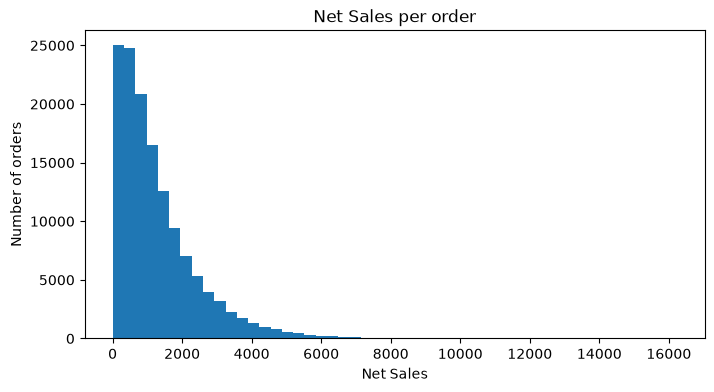

In [17]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(sales["net_sales"], bins=50)
ax.set_title("Net Sales per order")
ax.set_xlabel("Net Sales")
ax.set_ylabel("Number of orders")
plt.show()

Most orders are below about 2,000, with a long tail of larger orders.

In [18]:
display(sales.groupby("customer_segment")["net_sales"].median().round(2))
display(completed.groupby("delivery_status")["net_sales"].median().round(2))

customer_segment
Business    943.03
Consumer    952.42
Premium     946.82
VIP         960.15
Name: net_sales, dtype: float64

delivery_status
Delayed    934.00
Early      943.24
On Time    944.79
Name: net_sales, dtype: float64

Median Net Sales per order is 943 to 960 across segments (all orders) and 934 to 945 across delivery statuses (Completed). The "about the same per order" findings in Q4 to Q6b hold on medians.

## Discount by period and segment

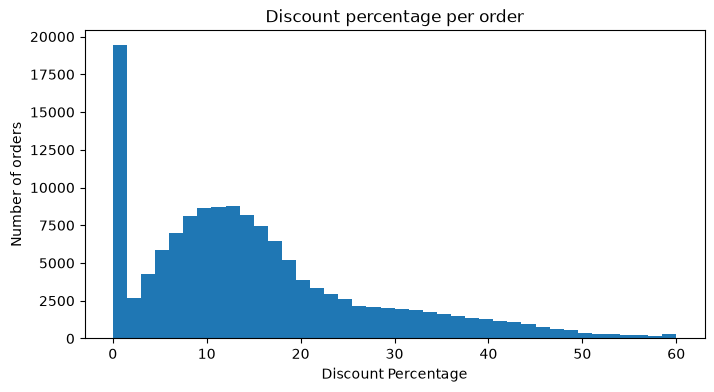

In [19]:
# Histogram of discount_pct
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(sales["discount_pct"], bins=40)
ax.set_title("Discount percentage per order")
ax.set_xlabel("Discount Percentage")
ax.set_ylabel("Number of orders")
plt.show()

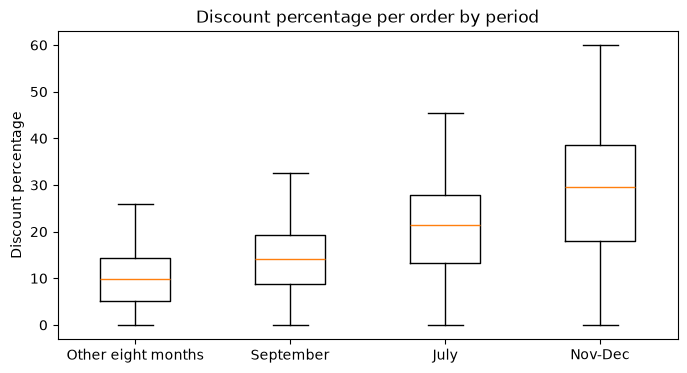

In [20]:
order = ["Other eight months", "September", "July", "Nov-Dec"]
fig, ax = plt.subplots(figsize=(8, 4))
ax.boxplot([sales.loc[sales["season_group"] == g, "discount_pct"] for g in order], tick_labels=order)
ax.set_title("Discount percentage per order by period")
ax.set_ylabel("Discount percentage")
plt.show()

In [21]:
quantiles = sales.groupby("season_group")["discount_pct"].quantile([0.25, 0.50, 0.75]).unstack()
quantiles.columns = ["25%", "50% (median)", "75%"]
zero_share = sales.groupby("season_group")["discount_pct"].apply(lambda x: x.eq(0).mean() * 100)
display(quantiles.join(zero_share.rename("Zero discount (%)")).round(2))

high = sales[sales["discount_pct"] > 20]
print("Share of orders discounted above 20% that fall in Nov-Dec:",
      round(high["order_month"].isin([11, 12]).mean() * 100, 2), "%")

,25%,50% (median),75%,Zero discount (%)
season_group,,,,
July,13.35,21.32,27.81,12.89
Nov-Dec,17.91,29.53,38.54,12.94
Other eight months,5.03,9.83,14.26,12.89
September,8.71,14.11,19.24,13.28


Share of orders discounted above 20% that fall in Nov-Dec: 67.03 %


Median discount per order: Nov-Dec 29.5%, July 21.3%, September 14.1%, other eight months 9.8%. The whole distribution shifts in those months. The share of orders with no discount is about 12.9% in every period. 67.0% of orders discounted above 20% fall in Nov-Dec, which hold 24.3% of orders.

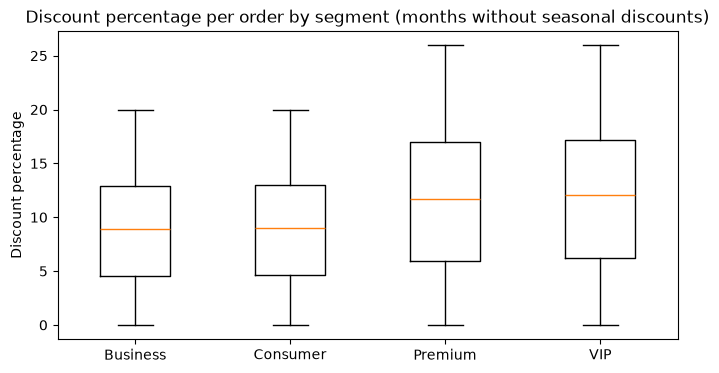

customer_segment
Business     8.89
Consumer     9.03
Premium     11.73
VIP         12.06
Name: discount_pct, dtype: float64

In [22]:
clean = sales[sales["season_group"] == "Other eight months"]
segments = ["Business", "Consumer", "Premium", "VIP"]
fig, ax = plt.subplots(figsize=(8, 4))
ax.boxplot([clean.loc[clean["customer_segment"] == s, "discount_pct"] for s in segments], tick_labels=segments)
ax.set_title("Discount percentage per order by segment (months without seasonal discounts)")
ax.set_ylabel("Discount percentage")
plt.show()
display(clean.groupby("customer_segment")["discount_pct"].median().round(2))

Outside Nov, Dec, July and September, median discount is Business 8.9%, Consumer 9.0%, Premium 11.7%, VIP 12.1%. The Premium and VIP gap is not a calendar effect.

## Summary
Results and open questions are recorded in docs/findings.md. This notebook cross-checks SQL totals, counts and ratings, and shows that discounts shift as a whole by period and segment.